In [1]:
# %%
# Code to validate the results of stochastic rasters for monthly products
# V1 - 2026-10-12 - JPK - adapted from the daily codes
# V2 - 2026-10-13 - station pairing fixed (sample points now come from the same
#                   test-station table that supplies index_no/cluster), NaN and
#                   member-count guard, one reliability bin per possible
#                   probability, small plotting/CSV fixes
# refer Zhang 2022 for validation scheme details


## A. Prediction intervals
# Use test station observations
# Calculate hits and misses at 50% confidence [0.25, 0.75] range; and 90% confidence range [0.05, 0.95] for the entire period
# Visualize for one randomly picked 2 year period for one tmax and tmin station

## B. reliability diagram
# for tmax --> 0.8 and 0.95 threshold observations
# for tmin --> 0.2 and 0.05 threshold observations


## C. Brier Scores

# %%
# A. PI
# first match the pixel to test station coordinates and get the cluster - store a df
# monthly loop - sample raster values [in array of 10 predictions] from each station location per day - get a df
# rearrange each point prediction in ascending and extract all the quartile values
# merge the day's actual observed value to the point observation df
# calculate hits or misses


# libraries
import os
import numpy as np  
import pandas as pd 
import matplotlib.pyplot as plt
import pyarrow
import xarray as xr 
import rioxarray as rxr
import rasterio
from tqdm import tqdm

# paths and files
tmax_test_stn = pd.read_csv(r"\\192.168.1.210\giis_home\Unclassified\Jeevan_Katel\ClimateDataWS\Temperature\Data\Processed\Split_stations\tmax_test_stations.csv")
tmin_test_stn = pd.read_csv(r"\\192.168.1.210\giis_home\Unclassified\Jeevan_Katel\ClimateDataWS\Temperature\Data\Processed\Split_stations\tmin_test_stations.csv")
insitu_tmax_raw = pd.read_parquet(r"\\192.168.1.210\giis_home\Unclassified\Jeevan_Katel\ClimateDataWS\Temperature\Data\Insitu\Cleaned\tmax_cleaned.parquet")
insitu_tmin_raw = pd.read_parquet(r"\\192.168.1.210\giis_home\Unclassified\Jeevan_Katel\ClimateDataWS\Temperature\Data\Insitu\Cleaned\tmin_cleaned.parquet")

tmax_train_df = r"\\192.168.1.210\giis_home\Unclassified\Jeevan_Katel\ClimateDataWS\Temperature\Data\Processed\Split_stations\tmax_train_stations.csv"
tmax_test_df = r"\\192.168.1.210\giis_home\Unclassified\Jeevan_Katel\ClimateDataWS\Temperature\Data\Processed\Split_stations\tmax_test_stations.csv"
tmin_train_df = r"\\192.168.1.210\giis_home\Unclassified\Jeevan_Katel\ClimateDataWS\Temperature\Data\Processed\Split_stations\tmin_train_stations.csv"
tmin_test_df = r"\\192.168.1.210\giis_home\Unclassified\Jeevan_Katel\ClimateDataWS\Temperature\Data\Processed\Split_stations\tmin_test_stations.csv"

min_valid_days = 20
N_MEMBERS = 10               # members per stochastic raster (bands)

start_year, start_month = 2001, 1
end_year, end_month = 2025, 12

In [2]:

# Preprocess the insitu data to aggregate for monthly observations

print("==========Aggregating insitu tmax to monthly means==============")
insitu_tmax_raw["date"] = pd.to_datetime(insitu_tmax_raw[['year', 'month', 'day']])
insitu_tmax_raw = insitu_tmax_raw.rename(columns = {'lat': 'y', 'long': 'x',
                                                            'max_temp': 'tmax'})
insitu_tmax_raw = insitu_tmax_raw[insitu_tmax_raw["tmax"] > -9999]

insitu_tmax_monthly = (
    insitu_tmax_raw
    .groupby(['index_no', 'y', "x", 'year', 'month'])
    .agg(
        tmax_average = ('tmax', 'mean'),
        valid_days = ('tmax', 'count')
    )
    .reset_index()
)

n_before_tmax = len(insitu_tmax_monthly)
insitu_tmax_monthly = insitu_tmax_monthly[insitu_tmax_monthly["valid_days"] >= min_valid_days].copy()
n_after_tmax = len(insitu_tmax_monthly)
print(f"    Station-months before completeness filter: {n_before_tmax:,}")
print(f"    Station-months after (>= {min_valid_days} valid days): {n_after_tmax:,}")
print(f"    Excluded: {n_before_tmax - n_after_tmax:,} ({100*(n_before_tmax-n_after_tmax)/n_before_tmax:.1f}%)")

# Filter to analysis period
insitu_tmax_monthly = insitu_tmax_monthly[
    (insitu_tmax_monthly["year"]    >=  start_year) &
    (insitu_tmax_monthly["year"]    <=  end_year)
].copy()

insitu_tmax_monthly[["x", "y"]] = insitu_tmax_monthly[["x", "y"]].round(5)

# Train/test split
train_ids_tmax = set(pd.read_csv(tmax_train_df)["index_no"])
test_ids_tmax = set(pd.read_csv(tmax_test_df)["index_no"])

insitu_tmax_monthly_train = insitu_tmax_monthly[insitu_tmax_monthly["index_no"].isin(train_ids_tmax)].copy()
insitu_tmax_monthly_test = insitu_tmax_monthly[insitu_tmax_monthly["index_no"].isin(test_ids_tmax)].copy()

print(f"\n  Train station-months: {len(insitu_tmax_monthly_train):,}")
print(f"  Test  station-months: {len(insitu_tmax_monthly_test):,}")

print("\n==========Aggregating insitu tmin to monthly means==============")
insitu_tmin_raw["date"] = pd.to_datetime(insitu_tmin_raw[['year', 'month', 'day']])
insitu_tmin_raw = insitu_tmin_raw.rename(columns = {'lat': 'y', 'long': 'x',
                                                            'min_temp': 'tmin'})
insitu_tmin_raw = insitu_tmin_raw[insitu_tmin_raw["tmin"] > -9999]

insitu_tmin_monthly = (
    insitu_tmin_raw
    .groupby(['index_no', 'y', "x", 'year', 'month'])
    .agg(
        tmin_average = ('tmin', 'mean'),
        valid_days = ('tmin', 'count')
    )
    .reset_index()
)

n_before_tmin = len(insitu_tmin_monthly)
insitu_tmin_monthly = insitu_tmin_monthly[insitu_tmin_monthly["valid_days"] >= min_valid_days].copy()
n_after_tmin = len(insitu_tmin_monthly)
print(f"    Station-months before completeness filter: {n_before_tmin:,}")
print(f"    Station-months after (>= {min_valid_days} valid days): {n_after_tmin:,}")
print(f"    Excluded: {n_before_tmin - n_after_tmin:,} ({100*(n_before_tmin-n_after_tmin)/n_before_tmin:.1f}%)")

# Filter to analysis period
insitu_tmin_monthly = insitu_tmin_monthly[
    (insitu_tmin_monthly["year"]    >=  start_year) &
    (insitu_tmin_monthly["year"]    <=  end_year)
].copy()

insitu_tmin_monthly[["x", "y"]] = insitu_tmin_monthly[["x", "y"]].round(5)

# Train/test split
train_ids_tmin = set(pd.read_csv(tmin_train_df)["index_no"])
test_ids_tmin = set(pd.read_csv(tmin_test_df)["index_no"])

insitu_tmin_monthly_train = insitu_tmin_monthly[insitu_tmin_monthly["index_no"].isin(train_ids_tmin)].copy()
insitu_tmin_monthly_test = insitu_tmin_monthly[insitu_tmin_monthly["index_no"].isin(test_ids_tmin)].copy()

print(f"\n  Train station-months: {len(insitu_tmin_monthly_train):,}")
print(f"  Test  station-months: {len(insitu_tmin_monthly_test):,}")

# get tmax_pq and tmin_pq
tmax_pq = insitu_tmax_monthly_test
tmin_pq = insitu_tmin_monthly_test

==========Aggregating insitu tmax to monthly means==============
    Station-months before completeness filter: 14,894
    Station-months after (>= 20 valid days): 14,804
    Excluded: 90 (0.6%)

  Train station-months: 11,310
  Test  station-months: 3,494

==========Aggregating insitu tmin to monthly means==============
    Station-months before completeness filter: 15,073
    Station-months after (>= 20 valid days): 14,983
    Excluded: 90 (0.6%)

  Train station-months: 11,560
  Test  station-months: 3,423


In [3]:
# %%
# Sample quantiles from stochastic rasters

month_range = pd.period_range(
    start = f"{start_year}-{start_month:02d}",
    end = f"{end_year}-{end_month:02d}",
    freq = "M"
)

for t_var in ["tmax", "tmin"]:
    results = []
    test_stn   = tmax_test_stn if t_var == "tmax" else tmin_test_stn
    # FIX: sample points come from the SAME table (same rows, same order) that
    # supplies index_no / cluster below, so pixel i always belongs to station i
    stn_points = list(zip(test_stn['long'], test_stn['lat']))
    for period in tqdm(month_range, desc = f"Monthly feature extraction for {t_var}"):
        file_path = fr"\\192.168.1.210\giis_home\Unclassified\Jeevan_Katel\ClimateDataWS\Temperature\Data\Processed\Monthly_downscaling\QRF_products\{t_var[:1].upper() + t_var[1:]}\Stochastic\{t_var}_QRFSt_{period.year}{period.month:02d}.tif"
        with rasterio.open(file_path) as src:
            crs = src.crs
            if crs == "EPSG:4326":
                sampled_values = list(src.sample(stn_points))                
                for i, value in enumerate(sampled_values):
                    results.append({
                    'year': f'{period.year}',
                    'month': f'{period.month}',
                    'index_no': test_stn.iloc[i]['index_no'],
                    'cluster':  test_stn.iloc[i]['cluster_id'],
                    'value_array':(np.sort(value))
                })
    if t_var == "tmax":
        tmax_sampled_df = pd.DataFrame(results)
        tmax_sampled_df['year'] = tmax_sampled_df['year'].astype(int)
        tmax_sampled_df['month'] = tmax_sampled_df['month'].astype(int)
        test_ids_tmax = set(tmax_test_stn["index_no"])
        tmax_test = tmax_pq[tmax_pq["index_no"].isin(test_ids_tmax)].copy()
        tmax_comparision_df = tmax_sampled_df.merge(tmax_test, on = ['year', 'month', 'index_no'], how = 'inner')
        tmax_comparision_df = tmax_comparision_df.rename(columns={'tmax_average': 'observation'})
        tmax_comparision_df = tmax_comparision_df[['year', 'month', 'index_no', 'cluster', 'observation', 'value_array']]
    if t_var == "tmin":
        tmin_sampled_df = pd.DataFrame(results)
        tmin_sampled_df['year'] = tmin_sampled_df['year'].astype(int)
        tmin_sampled_df['month'] = tmin_sampled_df['month'].astype(int)
        test_ids_tmin = set(tmin_test_stn["index_no"])
        tmin_test = tmin_pq[tmin_pq["index_no"].isin(test_ids_tmin)].copy()
        tmin_comparision_df = tmin_sampled_df.merge(tmin_test, on = ['year', 'month', 'index_no'], how = 'inner')
        tmin_comparision_df = tmin_comparision_df.rename(columns={'tmin_average': 'observation'})
        tmin_comparision_df = tmin_comparision_df[['year', 'month', 'index_no', 'cluster', 'observation', 'value_array']]

Monthly feature extraction for tmin: 100%|██████████| 300/300 [01:01<00:00,  4.90it/s]


In [4]:
# %%
# Drop cases with NaN pixels or an unexpected member count
def _valid_members(a):
    return (len(a) == N_MEMBERS) and (not np.isnan(a).any())

_ok = tmax_comparision_df['value_array'].apply(_valid_members)
print(f"tmax: dropped {(~_ok).sum()} of {len(_ok)} cases (NaN / member count)")
tmax_comparision_df = tmax_comparision_df[_ok].reset_index(drop=True)

_ok = tmin_comparision_df['value_array'].apply(_valid_members)
print(f"tmin: dropped {(~_ok).sum()} of {len(_ok)} cases (NaN / member count)")
tmin_comparision_df = tmin_comparision_df[_ok].reset_index(drop=True)

# %%
# add spatial columns (lat, long, elevation) to the comparision df for stations
tmax_pq1 = pd.read_parquet(
    r"\\192.168.1.210\giis_home\Unclassified\Jeevan_Katel\ClimateDataWS\Temperature\Data\Insitu\Cleaned\tmax_cleaned.parquet"
)
tmax_spatial = tmax_pq1[
    ["index_no", "lat", "long", "elevation"]
].drop_duplicates(subset=["index_no"])

tmin_pq1 = pd.read_parquet(
    r"\\192.168.1.210\giis_home\Unclassified\Jeevan_Katel\ClimateDataWS\Temperature\Data\Insitu\Cleaned\tmin_cleaned.parquet"
)
tmin_spatial = tmin_pq1[
    ["index_no", "lat", "long", "elevation"]
].drop_duplicates(subset=["index_no"])

# Merge with the unique station coordinates
tmax_comparision_df = pd.merge(
    tmax_comparision_df, tmax_spatial, on="index_no", how="left"
)
tmin_comparision_df = pd.merge(
    tmin_comparision_df, tmin_spatial, on="index_no", how="left"
)

tmax: dropped 0 of 3494 cases (NaN / member count)
tmin: dropped 0 of 3423 cases (NaN / member count)


In [5]:
# %%
# calculate columns q5, q25, q75, q95
# NOTE: with only 10 members, np.percentile puts q5/q95 almost at the ensemble
# min/max, so even a perfectly calibrated ensemble gives hit rates of only
# ~0.41 (50% interval) and ~0.76 (90% interval) -- compare against those, not 0.5/0.9
tmax_comparision_df['q5'] = tmax_comparision_df['value_array'].apply(lambda x: np.percentile(x, 5))
tmax_comparision_df['q25'] = tmax_comparision_df['value_array'].apply(lambda x: np.percentile(x, 25))
tmax_comparision_df['q50'] = tmax_comparision_df['value_array'].apply(lambda x: np.percentile(x, 50))
tmax_comparision_df['q75'] = tmax_comparision_df['value_array'].apply(lambda x: np.percentile(x, 75))
tmax_comparision_df['q95'] = tmax_comparision_df['value_array'].apply(lambda x: np.percentile(x, 95))


tmax_comparision_df['Hit_50'] = np.where(((tmax_comparision_df['observation']>= tmax_comparision_df['q25']) & (tmax_comparision_df['observation']<= tmax_comparision_df['q75'])), 1, 0)
tmax_comparision_df['Hit_90'] = np.where(((tmax_comparision_df['observation']>= tmax_comparision_df['q5']) & (tmax_comparision_df['observation']<= tmax_comparision_df['q95'])), 1, 0)

# Print overall hit rates
print(f"Overall 50th confidence hit rate for tmax: {tmax_comparision_df['Hit_50'].mean():.4f}")
print(f"Overall 90th confidence hit rate for tmax: {tmax_comparision_df['Hit_90'].mean():.4f}")

# Stratify by cluster
tmax_hit_rates_df = tmax_comparision_df.groupby('cluster')[['Hit_50', 'Hit_90']].mean().reset_index()

# Rename columns for better readability
tmax_hit_rates_df = tmax_hit_rates_df.rename(columns={
    'Hit_50': 'Hit_Rate_50_CI',
    'Hit_90': 'Hit_Rate_90_CI'
})
tmax_hit_rates_df.loc[len(tmax_hit_rates_df)] = ["Overall", tmax_comparision_df['Hit_50'].mean(), tmax_comparision_df['Hit_90'].mean()]

output_dir = r"\\192.168.1.210\giis_home\Unclassified\Jeevan_Katel\ClimateDataWS\Temperature\Data\Processed\Monthly_downscaling\Validation_results"
# Display the resulting dataframe
tmax_hit_rates_df.to_csv(os.path.join(output_dir, "Tmax_hit_rates.csv"), index = False)

Overall 50th confidence hit rate for tmax: 0.4416
Overall 90th confidence hit rate for tmax: 0.7994


In [6]:
# %%
# calculate columns q5, q25, q75, q95
tmin_comparision_df['q5'] = tmin_comparision_df['value_array'].apply(lambda x: np.percentile(x, 5))
tmin_comparision_df['q25'] = tmin_comparision_df['value_array'].apply(lambda x: np.percentile(x, 25))
tmin_comparision_df['q50'] = tmin_comparision_df['value_array'].apply(lambda x: np.percentile(x, 50))
tmin_comparision_df['q75'] = tmin_comparision_df['value_array'].apply(lambda x: np.percentile(x, 75))
tmin_comparision_df['q95'] = tmin_comparision_df['value_array'].apply(lambda x: np.percentile(x, 95))

tmin_comparision_df['Hit_50'] = np.where(((tmin_comparision_df['observation']>= tmin_comparision_df['q25']) & (tmin_comparision_df['observation']<= tmin_comparision_df['q75'])), 1, 0)
tmin_comparision_df['Hit_90'] = np.where(((tmin_comparision_df['observation']>= tmin_comparision_df['q5']) & (tmin_comparision_df['observation']<= tmin_comparision_df['q95'])), 1, 0)

# Print overall hit rates
print(f"Overall 50th confidence hit rate for tmin: {tmin_comparision_df['Hit_50'].mean():.4f}")
print(f"Overall 90th confidence hit rate for tmin: {tmin_comparision_df['Hit_90'].mean():.4f}")

# Stratify by cluster
tmin_hit_rates_df = tmin_comparision_df.groupby('cluster')[['Hit_50', 'Hit_90']].mean().reset_index()

# Rename columns for better readability
tmin_hit_rates_df = tmin_hit_rates_df.rename(columns={
    'Hit_50': 'Hit_Rate_50_CI',
    'Hit_90': 'Hit_Rate_90_CI'
})
tmin_hit_rates_df.loc[len(tmin_hit_rates_df)] = ["Overall", tmin_comparision_df['Hit_50'].mean(), tmin_comparision_df['Hit_90'].mean()]

output_dir = r"\\192.168.1.210\giis_home\Unclassified\Jeevan_Katel\ClimateDataWS\Temperature\Data\Processed\Monthly_downscaling\Validation_results"
# Display the resulting dataframe
tmin_hit_rates_df.to_csv(os.path.join(output_dir, "Tmin_hit_rates.csv"), index = False)

Overall 50th confidence hit rate for tmin: 0.4549
Overall 90th confidence hit rate for tmin: 0.8124


In [7]:
# Sanity check: station/pixel alignment and bias.
# For a calibrated product with CRPS ~0.9 degC, expect mean |q50 - obs| of about
# 1.0-1.5 degC. Several degC => stations and pixels are misaligned. ~1.2 degC but
# widely spread per-station mean errors => station-level bias.
for _name, _d in (("tmax", tmax_comparision_df), ("tmin", tmin_comparision_df)):
    _err = _d['q50'] - _d['observation']
    print(f"{_name}: mean |q50 - obs| = {_err.abs().mean():.2f} degC | mean bias = {_err.mean():+.2f} degC")
    print(_err.groupby(_d['index_no']).mean().describe()[['mean', 'std', 'min', 'max']].round(2))

tmax: mean |q50 - obs| = 1.32 degC | mean bias = -0.09 degC
mean   -0.12
std     1.46
min    -3.74
max     1.44
dtype: float64
tmin: mean |q50 - obs| = 1.14 degC | mean bias = +0.24 degC
mean    0.24
std     0.65
min    -0.83
max     1.14
dtype: float64


In [8]:
# %%
## B. reliability diagram
# find threshold observation value in temperature units
# convert the true observations to binary o(station, time)
# compute ensemble predicted probabilities f(s, t)
# bin and calculate coordinates

# filter dfs
tmax_rd_df = tmax_comparision_df[['year', 'month', 'index_no', 'observation', 'value_array']]
tmin_rd_df = tmin_comparision_df[['year', 'month', 'index_no', 'observation', 'value_array']]

# find threshold observations
tmax_threshold_80 = np.percentile(tmax_rd_df['observation'].to_numpy(), 80)
tmax_threshold_95 = np.percentile(tmax_rd_df['observation'].to_numpy(), 95)
tmin_threshold_20 = np.percentile(tmin_rd_df['observation'].to_numpy(), 20)
tmin_threshold_5 = np.percentile(tmin_rd_df['observation'].to_numpy(), 5)

# One bin per possible ensemble probability (k / N_MEMBERS, k = 0..N_MEMBERS):
# edges at -0.05, 0.05, ..., 1.05 for 10 members. Makes the Brier decomposition
# exact (brier_score == brier_score_check) because each bin holds one forecast value.
bin_edges  = (np.arange(N_MEMBERS + 2) - 0.5) / N_MEMBERS
bin_labels = [f"{k / N_MEMBERS:.2f}" for k in range(N_MEMBERS + 1)]

# ==========================================
# TMAX 80 (Greater than threshold)
# ==========================================
tmax_80_df = tmax_rd_df.copy()
tmax_80_df['binary_observation'] = np.where(tmax_80_df['observation'] > tmax_threshold_80, 1, 0)
tmax_80_df['ensemble_probability'] = tmax_80_df['value_array'].apply(
    lambda ensembles: np.count_nonzero(np.array(ensembles) > tmax_threshold_80) / len(ensembles)
)
tmax_80_df = tmax_80_df[['binary_observation', 'ensemble_probability']].reset_index(drop=True)

tmax_80_df['bin'] = pd.cut(tmax_80_df['ensemble_probability'], bins = bin_edges, labels = bin_labels, include_lowest=True)

tmax_80_rd = (tmax_80_df).groupby(tmax_80_df['bin'], observed = False).agg(
    observation_freq = ('binary_observation', 'mean'),
    predicted_prob = ('ensemble_probability', 'mean')
).reset_index()

# ==========================================
# TMAX 95 (Greater than threshold)
# ==========================================
tmax_95_df = tmax_rd_df.copy()
tmax_95_df['binary_observation'] = np.where(tmax_95_df['observation'] > tmax_threshold_95, 1, 0)
tmax_95_df['ensemble_probability'] = tmax_95_df['value_array'].apply(
    lambda ensembles: np.count_nonzero(np.array(ensembles) > tmax_threshold_95) / len(ensembles)
)
tmax_95_df = tmax_95_df[['binary_observation', 'ensemble_probability']].reset_index(drop=True)
tmax_95_df['bin'] = pd.cut(tmax_95_df['ensemble_probability'], bins=bin_edges, labels=bin_labels, include_lowest=True)

tmax_95_rd = tmax_95_df.groupby(tmax_95_df['bin'], observed=False).agg(
    observation_freq=('binary_observation', 'mean'),
    predicted_prob=('ensemble_probability', 'mean')
).reset_index()


# ==========================================
# TMIN 20 (Less than threshold)
# ==========================================
tmin_20_df = tmin_rd_df.copy()
tmin_20_df['binary_observation'] = np.where(tmin_20_df['observation'] < tmin_threshold_20, 1, 0)
tmin_20_df['ensemble_probability'] = tmin_20_df['value_array'].apply(
    lambda ensembles: np.count_nonzero(np.array(ensembles) < tmin_threshold_20) / len(ensembles)
)
tmin_20_df = tmin_20_df[['binary_observation', 'ensemble_probability']].reset_index(drop=True)
tmin_20_df['bin'] = pd.cut(tmin_20_df['ensemble_probability'], bins=bin_edges, labels=bin_labels, include_lowest=True)

tmin_20_rd = tmin_20_df.groupby(tmin_20_df['bin'], observed=False).agg(
    observation_freq=('binary_observation', 'mean'),
    predicted_prob=('ensemble_probability', 'mean')
).reset_index()


# ==========================================
# TMIN 5 (Less than threshold)
# ==========================================
tmin_5_df = tmin_rd_df.copy()
tmin_5_df['binary_observation'] = np.where(tmin_5_df['observation'] < tmin_threshold_5, 1, 0)
tmin_5_df['ensemble_probability'] = tmin_5_df['value_array'].apply(
    lambda ensembles: np.count_nonzero(np.array(ensembles) < tmin_threshold_5) / len(ensembles)
)
tmin_5_df = tmin_5_df[['binary_observation', 'ensemble_probability']].reset_index(drop=True)
tmin_5_df['bin'] = pd.cut(tmin_5_df['ensemble_probability'], bins=bin_edges, labels=bin_labels, include_lowest=True)

tmin_5_rd = tmin_5_df.groupby(tmin_5_df['bin'], observed=False).agg(
    observation_freq=('binary_observation', 'mean'),
    predicted_prob=('ensemble_probability', 'mean')
).reset_index()

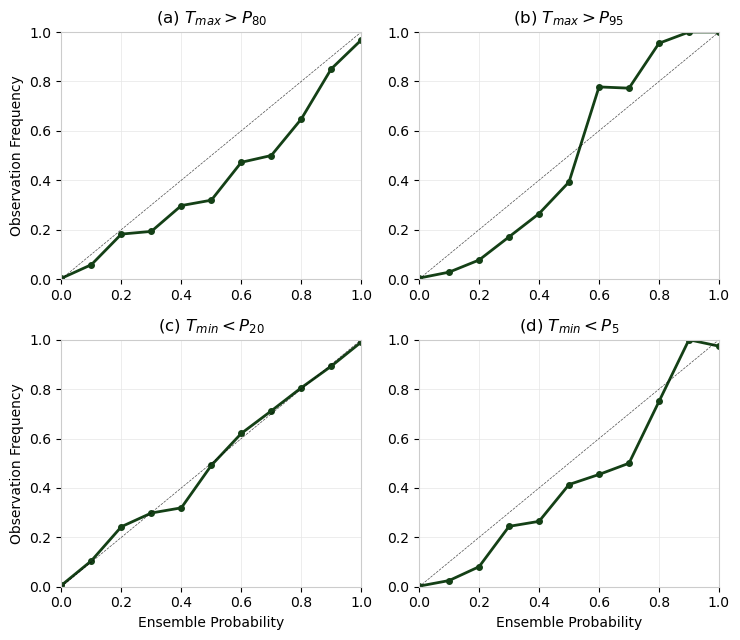

In [9]:
# %%
# RD visualization
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(7.5, 6.5))

ax[0, 0].plot(tmax_80_rd['predicted_prob'], tmax_80_rd['observation_freq'], color = '#144016', lw = 2, marker='o', markersize= 4)
ax[0, 0].axline((0, 0), slope=1, color='black', linestyle='--', alpha = 0.7, lw =0.5)
ax[0, 0].set_title(r"(a) $T_{max} > P_{80}$")
ax[0, 0].set_ylabel("Observation Frequency")

ax[0, 1].plot(tmax_95_rd['predicted_prob'], tmax_95_rd['observation_freq'], color = '#144016', lw = 2, marker='o', markersize= 4)
ax[0, 1].axline((0, 0), slope=1, color='black', linestyle='--', alpha = 0.7, lw =0.5)
ax[0, 1].set_title(r"(b) $T_{max} > P_{95}$")

ax[1, 0].plot(tmin_20_rd['predicted_prob'], tmin_20_rd['observation_freq'], color = '#144016', lw = 2, marker='o', markersize= 4)
ax[1, 0].axline((0, 0), slope=1, color='black', linestyle='--', alpha = 0.7, lw =0.5)
ax[1, 0].set_title(r"(c) $T_{min} < P_{20}$")
ax[1, 0].set_ylabel("Observation Frequency")
ax[1, 0].set_xlabel("Ensemble Probability")

ax[1, 1].plot(tmin_5_rd['predicted_prob'], tmin_5_rd['observation_freq'], color = '#144016', lw = 2, marker='o', markersize= 4)
ax[1, 1].axline((0, 0), slope=1, color='black', linestyle='--', alpha = 0.7, lw =0.5)
ax[1, 1].set_title("(d) $T_{min} < P_{5}$")
ax[1, 1].set_xlabel("Ensemble Probability")

for row in ax:
    for a in row:
        a.set_xlim(0, 1)
        a.set_ylim(0, 1)

        a.grid(True, which='both', color='#E6E6E6', linestyle='-', linewidth=0.5, zorder=0)
        
        # Optional: Lighten the outer bounding box (spines) for an even cleaner look
        for spine in a.spines.values():
            spine.set_color('#CCCCCC')
            spine.set_linewidth(0.8)

plt.tight_layout()
plt.savefig(os.path.join(output_dir, "Reliability_diagram_temp.tiff"), dpi = 300)
plt.show()

In [10]:
# %%
# C Brier Scores

def brier_decomposition(df, obs_col='binary_observation', prob_col='ensemble_probability', bin_col='bin'):
    n_total = len(df)
    obar = df[obs_col].mean()

    grouped = df.groupby(bin_col, observed=False).agg(
        n_k=(obs_col, 'count'),
        obar_k=(obs_col, 'mean'),
        fbar_k=(prob_col, 'mean')
    ).reset_index()
    grouped = grouped[grouped['n_k'] > 0]  # drop empty bins, else obar_k is NaN

    reliability = (grouped['n_k'] * (grouped['fbar_k'] - grouped['obar_k'])**2).sum() / n_total
    resolution  = (grouped['n_k'] * (grouped['obar_k'] - obar)**2).sum() / n_total
    uncertainty = obar * (1 - obar)

    brier_score = reliability - resolution + uncertainty
    brier_score_direct = ((df[prob_col] - df[obs_col])**2).mean()  # sanity check, equal to above with one bin per probability

    bss = 1 - brier_score / uncertainty if uncertainty > 0 else np.nan

    return {
        'brier_score': brier_score,
        'brier_score_check': brier_score_direct,
        'reliability': reliability,
        'resolution': resolution,
        'uncertainty': uncertainty,
        'brier_skill_score': bss,
        'base_rate': obar,
        'n_obs': n_total
    }

bs_results = {
    'tmax_80': brier_decomposition(tmax_80_df),
    'tmax_95': brier_decomposition(tmax_95_df),
    'tmin_20': brier_decomposition(tmin_20_df),
    'tmin_5':  brier_decomposition(tmin_5_df),
}

bs_summary = pd.DataFrame(bs_results).T
print(bs_summary)
bs_summary.to_csv(os.path.join(output_dir, "Brier_score.csv"), index_label="event")

         brier_score  brier_score_check  reliability  resolution  uncertainty  \
tmax_80     0.058540           0.058540     0.004404    0.105898     0.160034   
tmax_95     0.015057           0.015057     0.001472    0.033992     0.047577   
tmin_20     0.043430           0.043430     0.000239    0.116879     0.160070   
tmin_5      0.015995           0.015995     0.001158    0.032886     0.047723   

         brier_skill_score  base_rate   n_obs  
tmax_80           0.634201   0.200057  3494.0  
tmax_95           0.683520   0.050086  3494.0  
tmin_20           0.728683   0.200117  3423.0  
tmin_5            0.664845   0.050248  3423.0  


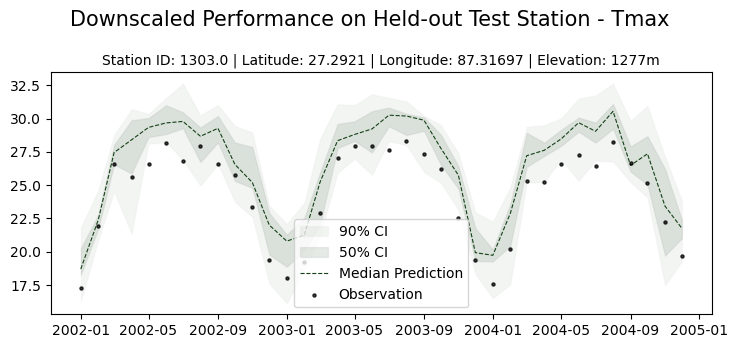

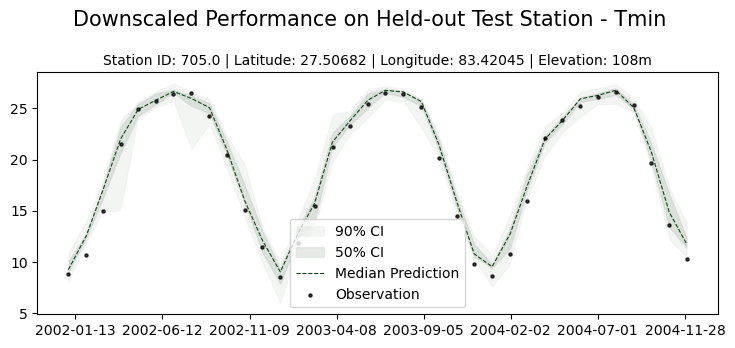

In [11]:
# %%
import random
import seaborn as sns
import matplotlib.ticker as ticker
random.seed(6)
random_number_idx = random.randint(0, len(tmax_comparision_df['index_no'].unique())-1)
#pick a random station
picked_idx = (tmax_comparision_df['index_no'].unique())[random_number_idx]

vis_tmax = tmax_comparision_df[(tmax_comparision_df['index_no'] == picked_idx) & (tmax_comparision_df['year'] >= 2002) & (tmax_comparision_df['year'] <= 2004) ].copy()
vis_tmax['date'] = pd.to_datetime(vis_tmax[['year', 'month']].assign(day=1))
fig, ax = plt.subplots(figsize=(7.5, 3.5))

ax.fill_between(vis_tmax['date'], vis_tmax['q5'], vis_tmax['q95'], 
                color='#144016', alpha=0.05, edgecolor='darkgray', 
                linewidth=1, label='90% CI')
ax.fill_between(vis_tmax['date'], vis_tmax['q25'], vis_tmax['q75'], 
                color='#144016', alpha=0.11, edgecolor='gray', 
                linewidth=1, label='50% CI')
ax.plot(vis_tmax['date'], vis_tmax['q50'], color='#144016', linestyle='--', linewidth=0.8, label = 'Median Prediction')
ax.scatter(vis_tmax['date'], vis_tmax['observation'], s=5, c='black', alpha=0.75, zorder=3, label='Observation')
ax.legend()
#ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
plt.suptitle("Downscaled Performance on Held-out Test Station - Tmax", fontsize = 15)
plt.title(f"Station ID: {picked_idx} | Latitude: {vis_tmax['lat'].iloc[0]} | Longitude: {vis_tmax['long'].iloc[0]} | Elevation: {vis_tmax['elevation'].iloc[0]}m", fontsize =10)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "Stochastic_PI_Tmax.png"), dpi = 300)
plt.show()

# %%
random.seed(89)
random_number_idx = random.randint(0, len(tmin_comparision_df['index_no'].unique())-1)
#pick a random station
picked_idx_tmin = (tmin_comparision_df['index_no'].unique())[random_number_idx]

vis_tmin = tmin_comparision_df[
    (tmin_comparision_df['index_no'] == picked_idx_tmin) &
    (tmin_comparision_df['year'] >= 2002) &
    (tmin_comparision_df['year'] <= 2004)
].copy()
vis_tmin['date'] = pd.to_datetime(vis_tmin[['year', 'month']].assign(day=1))

fig, ax = plt.subplots(figsize=(7.5, 3.5))

# 90 % confidence interval
ax.fill_between(
    vis_tmin['date'], vis_tmin['q5'], vis_tmin['q95'],
    color='#144016', alpha=0.05, edgecolor='darkgray',
    linewidth=1, label='90% CI'
)

# 50 % confidence interval
ax.fill_between(
    vis_tmin['date'], vis_tmin['q25'], vis_tmin['q75'],
    color='#144016', alpha=0.11, edgecolor='gray',
    linewidth=1, label='50% CI'
)

# Median prediction line
ax.plot(
    vis_tmin['date'], vis_tmin['q50'],
    color='#144016', linestyle='--', linewidth=0.8,
    label='Median Prediction'
)

# Observation points
ax.scatter(
    vis_tmin['date'], vis_tmin['observation'],
    s=5, c='black', alpha=0.75, zorder=3,
    label='Observation'
)

ax.legend()
ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=8))

plt.suptitle("Downscaled Performance on Held-out Test Station - Tmin", fontsize=15)
plt.title(
    f"Station ID: {picked_idx_tmin} | Latitude: {vis_tmin['lat'].iloc[0]} | "
    f"Longitude: {vis_tmin['long'].iloc[0]} | Elevation: {vis_tmin['elevation'].iloc[0]}m",
    fontsize=10
)

plt.tight_layout()
plt.savefig(os.path.join(output_dir, "Stochastic_PI_Tmin.png"), dpi = 300)    
plt.show()